# imports and initialization

In [1]:
import numpy as np
import os
import pickle
import matplotlib.pyplot as plt
import matplotlib
from g2p_en import G2p

from nejm_b2txt_utils.general_utils import *

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'

g2p = G2p()

# load Copy Task evaluation data

In [2]:
# load pickled data
with open('../../data/doi_10_5061_dryad_dncjsxm85__v20250703/t15_copyTask.pkl', 'rb') as f:
    dat = pickle.load(f)

# plot decoded phoneme logits from an example trial

### Phoneme logits for a second trial
- Cue "really well regulated" is decoded as "really well wreck a looted"; raw phonemes `R EH G Y AH L EY T AH D` come out as `R EH K AH L UW T AH D`
- Model output = 41 classes (`LOGIT_PHONE_DEF`): `BLANK` (CTC no-output), `SIL` (word boundary) and 39 ARPAbet phonemes
- x-axis: time from trial start; one output frame every 80 ms (20 ms neural bins, RNN stride 4)
- Top: raw logit of each class over time; `BLANK` is light grey and `SIL` is dotted black
- Middle: the same logits as a heatmap (class × time)
- Bottom: softmax over the 41 classes per frame, so each column sums to 1; red circles mark the most likely non-`BLANK` class

In [7]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

trl = 500
FRAME_S = 0.08  # one RNN output frame = 4 x 20 ms neural bins (stride 4)

logits = dat['decoded_logits'][trl]  # (n_frames, 41)
probs = np.exp(logits - logits.max(axis=1, keepdims=True))
probs /= probs.sum(axis=1, keepdims=True)
t = np.arange(logits.shape[0]) * FRAME_S

print(f"cue words:               {dat['cue_sentence'][trl]}")
print(f"cue phonemes:            {' '.join(dat['cue_sentence_phonemes'][trl]).replace('SIL',' | ')}")
print(f"decoded phonemes (raw):  {' '.join(dat['decoded_phonemes_raw'][trl]).replace('SIL',' | ')}")
print(f"decoded words:           {dat['decoded_sentence'][trl]}")
print(f"decoded phonemes:        {' '.join(dat['decoded_sentence_phonemes'][trl]).replace('SIL',' | ')}")

fig = make_subplots(
    rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.06,
    row_heights=[0.3, 0.35, 0.35],
    subplot_titles=(
        'Raw logit per phoneme class over time (one line per class)',
        'Raw logits (heatmap)',
        'Softmax probability per frame (each column sums to 1)',
    ),
)

# line plot: BLANK and SIL drawn in grey/black so the phoneme traces stand out
for p, phone in enumerate(LOGIT_PHONE_DEF):
    line = dict(width=1)
    if phone == 'BLANK':
        line = dict(width=1, color='lightgrey')
    elif phone == 'SIL':
        line = dict(width=1, color='black', dash='dot')
    fig.add_trace(go.Scatter(
        x=t, y=logits[:, p], mode='lines', name=phone, line=line, legendgroup=phone,
        hovertemplate=f'{phone}<br>t = %{{x:.2f}} s<br>logit = %{{y:.2f}}<extra></extra>',
    ), row=1, col=1)

fig.add_trace(go.Heatmap(
    x=t, y=LOGIT_PHONE_DEF, z=logits.T, colorscale='Blues',
    colorbar=dict(title='logit', y=0.5, len=0.33),
    hovertemplate='%{y}<br>t = %{x:.2f} s<br>logit = %{z:.2f}<extra></extra>',
), row=2, col=1)

fig.add_trace(go.Heatmap(
    x=t, y=LOGIT_PHONE_DEF, z=probs.T, colorscale='Blues', zmin=0, zmax=1,
    colorbar=dict(title='P(class)', y=0.15, len=0.33),
    hovertemplate='%{y}<br>t = %{x:.2f} s<br>P = %{z:.3f}<extra></extra>',
), row=3, col=1)

# mark the argmax class at each frame (skipping BLANK) on the probability heatmap
top = probs.argmax(axis=1)
keep = top != 0
fig.add_trace(go.Scatter(
    x=t[keep], y=[LOGIT_PHONE_DEF[i] for i in top[keep]], mode='markers',
    marker=dict(symbol='circle-open', color='red', size=6), name='argmax (non-BLANK)',
    hovertemplate='argmax: %{y}<br>t = %{x:.2f} s<extra></extra>',
), row=3, col=1)

for r in (2, 3):
    fig.update_yaxes(title_text='Output class', autorange='reversed', tickfont=dict(size=8), row=r, col=1)
fig.update_yaxes(title_text='Logit (unnormalised)', row=1, col=1)
fig.update_xaxes(title_text=f'Time from trial start (s), {int(FRAME_S*1000)} ms per output frame', row=3, col=1)

fig.update_layout(
    height=1100, template='plotly_white', hovermode='closest',
    title=dict(text=(
        f'Trial {trl}, post-implant day {dat["post_implant_day"][trl]}, vocab {dat["vocab_size"][trl]:,}<br>'
        f'<sup>cue: "{dat["cue_sentence"][trl]}" &nbsp;|&nbsp; decoded: "{dat["decoded_sentence"][trl]}"</sup>'
    )),
    legend=dict(title='Class', font=dict(size=9), tracegroupgap=0),
)
fig.show()

cue words:               they can pretty much get everybody there
cue phonemes:            DH EY  |  K AE N  |  P R IH T IY  |  M AH CH  |  G EH T  |  EH V R IY B AA D IY  |  DH EH R  | 
decoded phonemes (raw):  DH EY  |  K AE N  |  B R IH T IY  |  M AH N CH  |  G EH T  |  EH V R IY B AA D IY  |  DH EH R  | 
decoded words:           they can pretty much get everybody there
decoded phonemes:        DH EY  |  K AE N  |  P R IH T IY  |  M AH CH  |  G EH T  |  EH V R IY B AA D IY  |  DH EH R  | 


# calculate and plot phoneme error rate and word error rate for each session

In [5]:
unique_days = np.sort(np.unique(dat['post_implant_day']))

rper_by_day = {} # raw phoneme error rate
wer_by_day = {} # word error rate

for d, day in enumerate(unique_days):
    for v, vocab_size in enumerate(np.array((50,125000))):

        ind = [i for i in np.where(dat["post_implant_day"]==day)[0] if i in np.where(dat["vocab_size"]==vocab_size)[0]]

        if len(ind)==0:
            continue

        rper_day = calculate_aggregate_error_rate(
            r = [dat['cue_sentence_phonemes'][i] for i in ind],
            h = [dat['decoded_phonemes_raw'][i] for i in ind],
        )

        wer_day = calculate_aggregate_error_rate(
            r = [dat['cue_sentence'][i].split() for i in ind],
            h = [dat['decoded_sentence'][i].split() for i in ind],
        )
        
        print(f'Day {day}, vocab size {vocab_size}, rPER: {rper_day[0]*100:.2f}%, WER: {wer_day[0]*100:.2f}%')

        rper_by_day[(day, vocab_size)] = rper_day
        wer_by_day[(day, vocab_size)] = wer_day


Day 25, vocab size 50, rPER: 1.67%, WER: 0.44%
Day 27, vocab size 50, rPER: 2.11%, WER: 0.00%
Day 27, vocab size 125000, rPER: 15.36%, WER: 9.84%
Day 34, vocab size 125000, rPER: 12.89%, WER: 13.61%
Day 46, vocab size 125000, rPER: 9.50%, WER: 4.61%
Day 48, vocab size 125000, rPER: 11.70%, WER: 5.40%
Day 69, vocab size 125000, rPER: 12.45%, WER: 6.15%
Day 74, vocab size 125000, rPER: 10.17%, WER: 3.89%
Day 76, vocab size 125000, rPER: 10.36%, WER: 4.60%
Day 81, vocab size 125000, rPER: 10.58%, WER: 4.06%
Day 83, vocab size 125000, rPER: 10.13%, WER: 4.37%
Day 88, vocab size 125000, rPER: 6.93%, WER: 2.54%
Day 90, vocab size 125000, rPER: 7.27%, WER: 3.25%
Day 95, vocab size 125000, rPER: 7.76%, WER: 0.99%
Day 223, vocab size 125000, rPER: 9.33%, WER: 3.10%
Day 244, vocab size 125000, rPER: 7.33%, WER: 1.82%


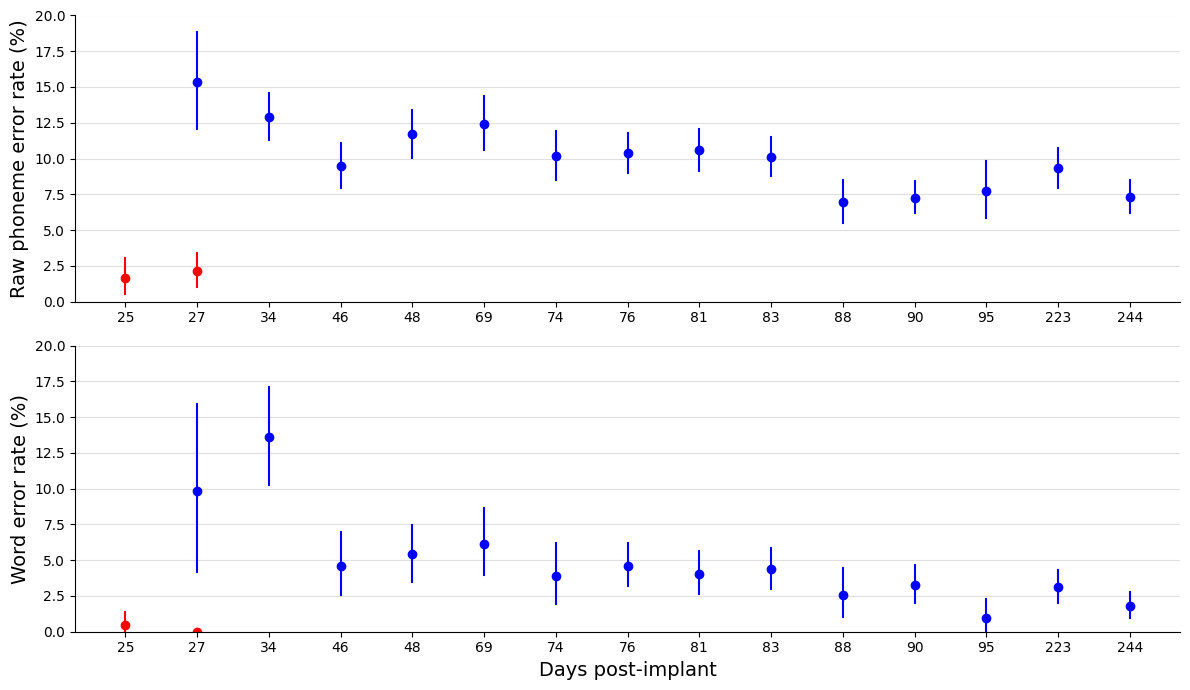

In [6]:
plt.figure(figsize=(12, 7))
ax1 = plt.subplot(211)
ax2 = plt.subplot(212)

for d, day in enumerate(unique_days):
    ind = np.array(dat["post_implant_day"])==day
    for v, vocab_size in enumerate(np.unique(np.array(dat["vocab_size"])[ind])):

        if (day, vocab_size) in rper_by_day:
            rper_day = rper_by_day[(day, vocab_size)]
            ax1.plot(d, 100*rper_day[0], 'o', color='r' if vocab_size==50 else 'b', label=f'{vocab_size} words')
            ax1.plot([d, d], [100*rper_day[1], 100*rper_day[2]], color='r' if vocab_size==50 else 'b')

        if (day, vocab_size) in wer_by_day:
            wer_day = wer_by_day[(day, vocab_size)]
            ax2.plot(d, 100*wer_day[0], 'o', color='r' if vocab_size==50 else 'b', label=f'{vocab_size} words')
            ax2.plot([d, d], [100*wer_day[1], 100*wer_day[2]], color='r' if vocab_size==50 else 'b')

# axis labels
ax1.set_ylabel('Raw phoneme error rate (%)', fontsize=14)
ax2.set_xlabel('Days post-implant', fontsize=14)
ax2.set_ylabel('Word error rate (%)', fontsize=14)

# tick labels
ax1.set_xticks(np.arange(len(unique_days)))
ax1.set_xticklabels([f'{d}' for d in unique_days])
ax2.set_xticks(np.arange(len(unique_days)))
ax2.set_xticklabels([f'{d}' for d in unique_days])

# y limits
ax1.set_ylim([0, 20])
ax2.set_ylim([0, 20])

# remove splines
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# grid
ax1.grid(axis='y', alpha=0.4)
ax2.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()